# Systems of differential equations and phase portraits

A **system** of two first-order ODEs has two unknown functions $x(t)$, $y(t)$:
$$ x'(t) = f\big(t, x(t), y(t)\big), \qquad y'(t) = g\big(t, x(t), y(t)\big), \qquad x(t_0) = x_0, \quad y(t_0) = y_0. $$
Each equation can contain **both** unknowns, so the equations must be solved **together**. We need **one initial condition per unknown**.


In [25]:
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp
from scipy.integrate import solve_ivp

t = sp.symbols("t")
x = sp.Function("x")          # unknown function x(t)
y = sp.Function("y")          # unknown function y(t)

# Part 1. Solving a system with SymPy

We solve
$$ x'(t) = -\tfrac14 x(t) + y(t), \qquad y'(t) = -x(t) - \tfrac14 y(t), \qquad x(0) = 1, \quad y(0) = 0. $$

### Step 1: write the equations

Same as for one equation, but now there are **two** unknown functions and **two** equations, collected in a **list**.

As before, **use exact numbers**: `x(t)/4`, not `0.25*x(t)`.

In [26]:
eqs = [sp.Eq(x(t).diff(t), -x(t)/4 + y(t)),
       sp.Eq(y(t).diff(t), -x(t) - y(t)/4)]
eqs

[Eq(Derivative(x(t), t), -x(t)/4 + y(t)),
 Eq(Derivative(y(t), t), -x(t) - y(t)/4)]

### Step 2: solve the initial value problem

`sp.dsolve` accepts the list of equations. The initial conditions go in `ics=`, one for each unknown.

The answer is a **list**: `sol[0]` is the equation for $x(t)$ and `sol[1]` the equation for $y(t)$. Their right sides are `sol[0].rhs` and `sol[1].rhs`.

In [27]:
sol = sp.dsolve(eqs, ics={x(0): 1, y(0): 0})
X, Y = sol[0].rhs, sol[1].rhs
display(sol[0], sol[1])

Eq(x(t), exp(-t/4)*cos(t))

Eq(y(t), -exp(-t/4)*sin(t))

Both functions are a decaying factor $e^{-t/4}$ times an oscillation ($\cos t$, $\sin t$).

### Step 3: check the answer

**Always check.** `sp.checkodesol` works for systems too: it returns `(True, [0, 0])`, one zero per equation.

In [28]:
print("checkodesol:", sp.checkodesol(eqs, sol))
print("x(0) =", X.subs(t, 0), "   y(0) =", Y.subs(t, 0))

checkodesol: (True, [0, 0])
x(0) = 1    y(0) = 0


### Step 4: plot $x(t)$ and $y(t)$ with `sp.plot`

SymPy can plot its formulas **directly**, without `lambdify`:
```python
sp.plot(expr1, expr2, (t, t_start, t_end))
```
Several expressions in one call give several curves in one picture.

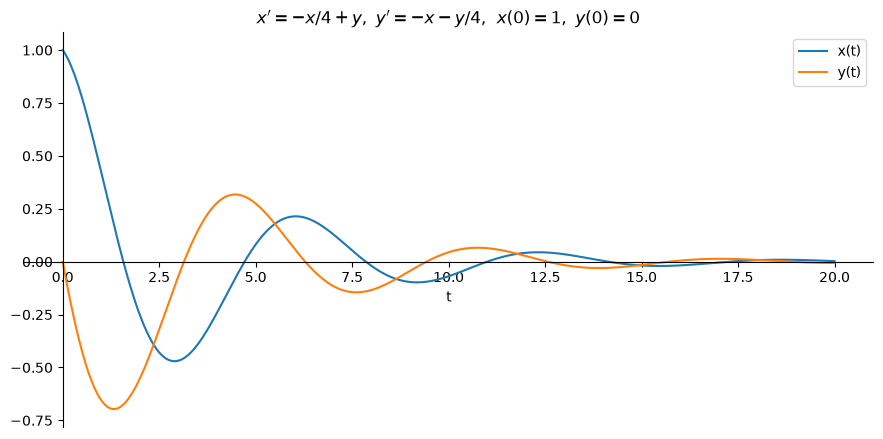

In [29]:
sp.plot(X, Y, (t, 0, 20),
        legend=True, label=["x(t)", "y(t)"],
        xlabel="t", ylabel="",
        title=r"$x' = -x/4 + y,\ y' = -x - y/4$,  $x(0) = 1,\ y(0) = 0$",
        size=(9, 4.5));

Both $x(t)$ and $y(t)$ oscillate and die out. (The `;` at the end stops Jupyter from printing the plot object.)

### Step 5: the phase plane with `sp.plot_parametric`

Forget the time axis: at each time $t$, plot the **point** $\big(x(t), y(t)\big)$. As $t$ runs, the point moves along a curve in the $xy$-plane, the **phase plane**. This curve is a **trajectory**.

A curve given by $\big(x(t), y(t)\big)$ is a **parametric curve**:
```python
sp.plot_parametric((x_expr, y_expr, (t, t_start, t_end)))
```

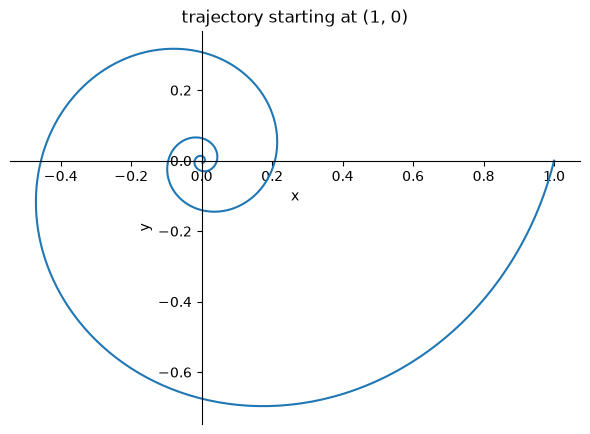

In [30]:
sp.plot_parametric((X, Y, (t, 0, 20)),
                   xlabel="x", ylabel="y",
                   title="trajectory starting at (1, 0)",
                   aspect_ratio=(1, 1), size=(6, 6));

The point starts at $(1, 0)$, turns **clockwise** and **spirals** into $(0, 0)$.

### Step 6: several trajectories

Different initial values give different trajectories. We solve the IVP for several starting points and give all curves to **one** `plot_parametric` call. The picture of many trajectories is the **phase portrait**.

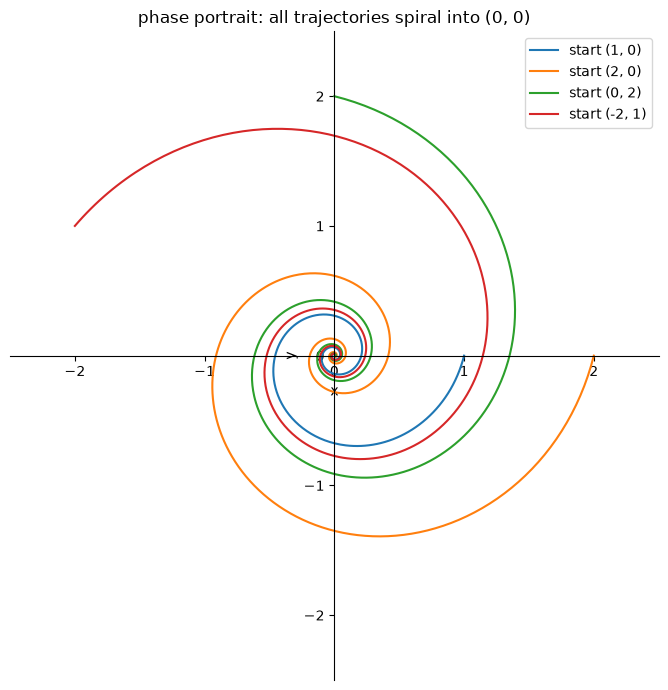

In [31]:
starts = [(1, 0), (2, 0), (0, 2), (-2, 1)]
curves, labels = [], []
for x0, y0 in starts:
    s = sp.dsolve(eqs, ics={x(0): x0, y(0): y0})
    curves.append((s[0].rhs, s[1].rhs, (t, 0, 20)))
    labels.append(f"start ({x0}, {y0})")

sp.plot_parametric(*curves, legend=True, label=labels,
                   xlabel="x", ylabel="y", title="phase portrait: all trajectories spiral into (0, 0)",
                   xlim=(-2.5, 2.5), ylim=(-2.5, 2.5),
                   aspect_ratio=(1, 1), size=(7, 7));

- Every trajectory spirals into the origin: $(0, 0)$ is an **equilibrium** (there $x'(t) = y'(t) = 0$), and all solutions approach it.
- Trajectories **never cross**: through each point passes exactly one solution.

`*curves` passes the list elements as separate arguments: `plot_parametric(curve1, curve2, ...)`.

# Part 2. Solving a system with SciPy

For `solve_ivp`, a system is no harder than one equation. The unknown is now a **vector** $u = \big(x(t), y(t)\big)$:
- `f(t, u)` receives `u` as an array: $x$ is `u[0]`, $y$ is `u[1]`;
- `f` returns the **list of derivatives** $[x'(t), y'(t)]$, in the same order;
- the initial value is the list `[x0, y0]`.

## Part 2A. The system from Part 1

$$ x'(t) = -\tfrac14 x(t) + y(t), \qquad y'(t) = -x(t) - \tfrac14 y(t), \qquad x(0) = 1, \quad y(0) = 0. $$

### Step 1: solve

In [32]:
def F(t, u):
    x, y = u
    return [-x/4 + y, -x - y/4]

tt = np.linspace(0, 20, 401)          # step 0.05
sol = solve_ivp(F, (0, 20), [1, 0], t_eval=tt, rtol=1e-10, atol=1e-12)
print("success:", sol.success)
print("shape of sol.y:", sol.y.shape)

success: True
shape of sol.y: (2, 401)


`sol.y` now has **two rows**: `sol.y[0]` is $x(t)$ and `sol.y[1]` is $y(t)$.

### Step 2: check against the exact SymPy solution

Here we do need `lambdify`: to compare numbers, we turn the SymPy formulas from Part 1 into NumPy functions.

In [33]:
X_num = sp.lambdify(t, X, "numpy")
Y_num = sp.lambdify(t, Y, "numpy")
err_x = np.max(np.abs(sol.y[0] - X_num(tt)))
err_y = np.max(np.abs(sol.y[1] - Y_num(tt)))
print(f"max error in x: {err_x:.1e}    max error in y: {err_y:.1e}")

max error in x: 2.7e-11    max error in y: 2.7e-11


### Step 3: plot $x(t)$, $y(t)$, the trajectory, and a delay embedding

The third panel is a **delay embedding**. Suppose we could measure only **one** of the two functions, say $x(t)$. Plot $x(t)$ against the **same** function a fixed time $\tau$ later, $x(t + \tau)$. Here $\tau = 5$.

The picture has the same shape as the true phase portrait in the middle panel: a spiral into $(0, 0)$. One measured variable is enough to see the behavior of the whole system. The embedded spiral is flatter, because $x(t+5)$ has decayed by the extra factor $e^{-5/4} \approx 0.29$; try a smaller $\tau$, e.g. $\tau = 1.5$. (This is the idea behind **Takens' theorem**, used to study systems from measured data.)

In the code: `tt` has step $0.05$, so $\tau = 5$ is a shift of `k = 100` points. The pairs $\big(x(t), x(t+\tau)\big)$ are `sol.y[0][:-k]` (all but the last `k` values) and `sol.y[0][k:]` (all but the first `k`).

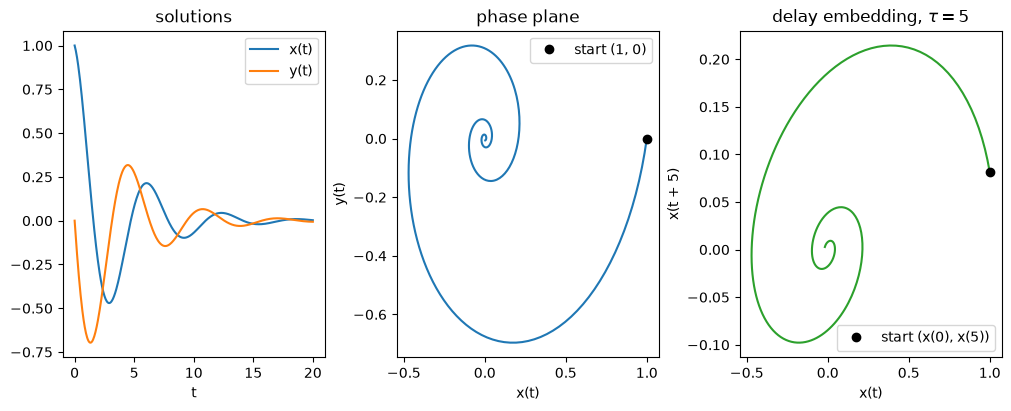

In [34]:
tau = 5
k = round(tau / (tt[1] - tt[0]))        # shift in number of points

fig, axs = plt.subplots(1, 3, figsize=(10, 4), constrained_layout=True)
axs[0].plot(sol.t, sol.y[0], label="x(t)")
axs[0].plot(sol.t, sol.y[1], label="y(t)")
axs[0].set_xlabel("t"); axs[0].legend(); axs[0].set_title("solutions")

axs[1].plot(sol.y[0], sol.y[1])
axs[1].plot(1, 0, "o", color="k", label="start (1, 0)")
axs[1].set_xlabel("x(t)"); axs[1].set_ylabel("y(t)")
axs[1].legend(); axs[1].set_title("phase plane")

axs[2].plot(sol.y[0][:-k], sol.y[0][k:], color="tab:green")
axs[2].plot(sol.y[0][0], sol.y[0][k], "o", color="k", label=f"start (x(0), x({tau}))")
axs[2].set_xlabel("x(t)"); axs[2].set_ylabel(f"x(t + {tau})")
axs[2].legend(); axs[2].set_title(rf"delay embedding, $\tau = {tau}$")
plt.show()

## Part 2B. The direction field with `streamplot`

The system tells us the **velocity** of the point $\big(x(t), y(t)\big)$ at **every** position, without solving anything:
$$ \big(x'(t), y'(t)\big) = \big(-\tfrac14 x(t) + y(t),\ -x(t) - \tfrac14 y(t)\big). $$
These velocity vectors on a grid form the **direction field**. Trajectories follow it.

### Step 1: compute the velocities on a grid

`np.meshgrid` makes a grid of points `Xg`, `Yg`. A useful trick: `F(0, [Xg, Yg])` also works on the **whole grid** at once, so the same function gives the velocities `U` $= x'$ and `V` $= y'$ at every grid point.

In [35]:
xs = np.linspace(-2.5, 2.5, 21)
Xg, Yg = np.meshgrid(xs, xs)
U, V = F(0, [Xg, Yg])
print("grid shape:", Xg.shape, "  velocity at (1, 0):", F(0, [1, 0]))

grid shape: (21, 21)   velocity at (1, 0): [-0.25, -1.0]


### Step 2: `streamplot`

`ax.streamplot(Xg, Yg, U, V)` draws curves that **follow** the direction field: it looks like a picture of the trajectories.

Useful options:
- `density=1.5`: more (or fewer) curves;
- `color="gray"`, `linewidth=0.8`, `arrowsize=1.2`.

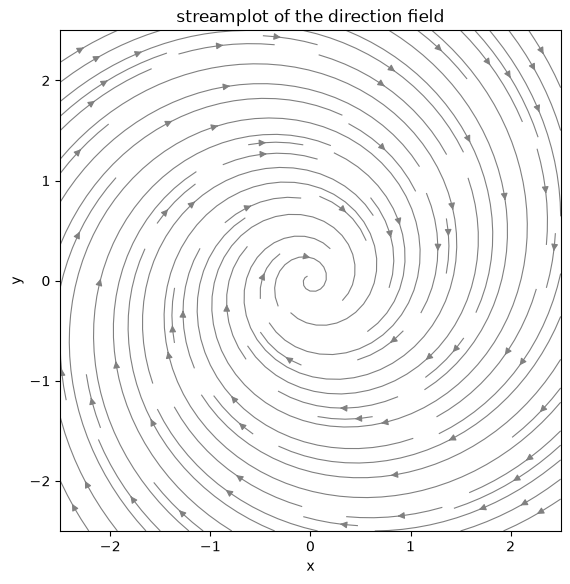

In [36]:
fig, ax = plt.subplots(figsize=(6.5, 6.5))
ax.streamplot(Xg, Yg, U, V, color="gray", density=1.2, linewidth=0.8)
ax.set_xlabel("x"); ax.set_ylabel("y"); ax.set_aspect("equal")
ax.set_title("streamplot of the direction field")
plt.show()

### Step 3: the phase portrait: streamplot plus trajectories

We put the streamplot in light gray and draw the solutions from several starting points on top.

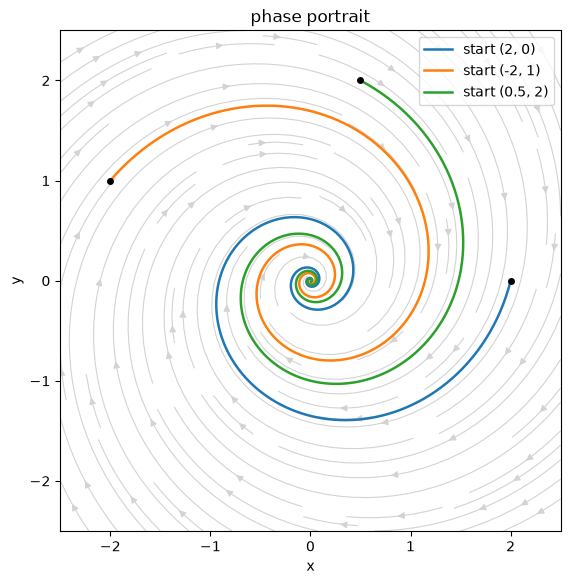

In [37]:
fig, ax = plt.subplots(figsize=(6.5, 6.5))
ax.streamplot(Xg, Yg, U, V, color="lightgray", density=1.2, linewidth=0.8)

tt = np.linspace(0, 20, 500)
for x0, y0 in [(2, 0), (-2, 1), (0.5, 2)]:
    s = solve_ivp(F, (0, 20), [x0, y0], t_eval=tt, rtol=1e-8)
    ax.plot(s.y[0], s.y[1], lw=1.8, label=f"start ({x0}, {y0})")
    ax.plot(x0, y0, "o", color="k", ms=4)

ax.set_xlim(-2.5, 2.5); ax.set_ylim(-2.5, 2.5); ax.set_aspect("equal")
ax.set_xlabel("x"); ax.set_ylabel("y"); ax.legend(loc="upper right")
ax.set_title("phase portrait")
plt.show()

## Part 2C. A nonlinear system: predator and prey

$$ x'(t) = x(t) - x(t)\,y(t), \qquad y'(t) = -y(t) + x(t)\,y(t), $$
$x(t)$ = prey (rabbits), $y(t)$ = predators (foxes), in suitable units. SymPy finds no formula for this system, but for `solve_ivp` it is just another `F`.

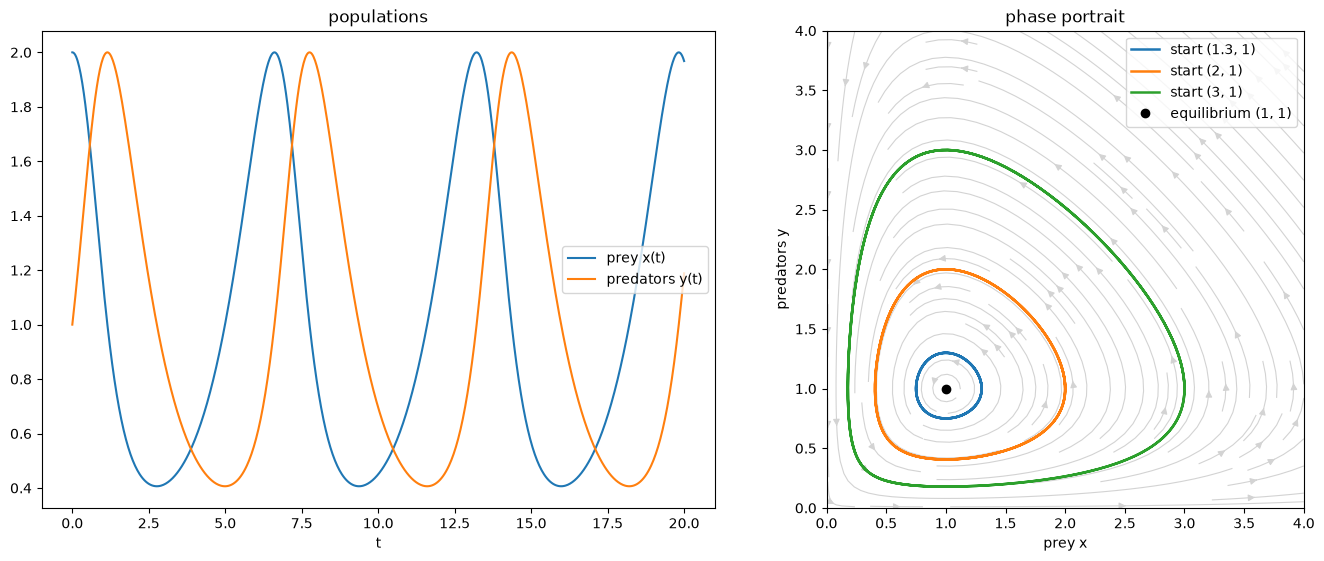

In [38]:
def LV(t, u):
    x, y = u
    return [x - x*y, -y + x*y]

tt = np.linspace(0, 20, 800)
sol = solve_ivp(LV, (0, 20), [2, 1], t_eval=tt, rtol=1e-9, atol=1e-12)

xs = np.linspace(0.01, 4, 21)
Xg, Yg = np.meshgrid(xs, xs)
U, V = LV(0, [Xg, Yg])

fig, axs = plt.subplots(1, 2, figsize=(14, 5.5), constrained_layout=True)
axs[0].plot(tt, sol.y[0], label="prey x(t)")
axs[0].plot(tt, sol.y[1], label="predators y(t)")
axs[0].set_xlabel("t"); axs[0].legend(); axs[0].set_title("populations")

axs[1].streamplot(Xg, Yg, U, V, color="lightgray", density=1.2, linewidth=0.8)
for x0 in [1.3, 2, 3]:
    s = solve_ivp(LV, (0, 20), [x0, 1], t_eval=tt, rtol=1e-9, atol=1e-12)
    axs[1].plot(s.y[0], s.y[1], lw=1.8, label=f"start ({x0}, 1)")
axs[1].plot(1, 1, "o", color="k", label="equilibrium (1, 1)")
axs[1].set_xlim(0, 4); axs[1].set_ylim(0, 4); axs[1].set_aspect("equal")
axs[1].set_xlabel("prey x"); axs[1].set_ylabel("predators y"); axs[1].legend(loc="upper right")
axs[1].set_title("phase portrait")
plt.show()

- The populations are **periodic**: the trajectories are **closed curves** around the equilibrium $(1, 1)$, where $x'(t) = y'(t) = 0$.
- The predators peak **after** the prey: first many rabbits, then many foxes, then few rabbits, then few foxes.

## Summary

| task | SymPy | SciPy |
|---|---|---|
| unknowns | `x = sp.Function("x")`, `y = sp.Function("y")` | vector `u = [x, y]` |
| equations | `eqs = [sp.Eq(x(t).diff(t), ...), sp.Eq(y(t).diff(t), ...)]` | `def F(t, u): x, y = u; return [x', y']` |
| solve IVP | `sol = sp.dsolve(eqs, ics={x(0): x0, y(0): y0})` | `sol = solve_ivp(F, (t0, T), [x0, y0])` |
| results | `sol[0].rhs`, `sol[1].rhs` | `sol.y[0]`, `sol.y[1]` |
| check | `sp.checkodesol(eqs, sol)` | `sol.success` |
| plot $x(t), y(t)$ | `sp.plot(sol[0].rhs, sol[1].rhs, (t, 0, T))` | `ax.plot(sol.t, sol.y[0])`, `ax.plot(sol.t, sol.y[1])` |
| trajectory | `sp.plot_parametric((sol[0].rhs, sol[1].rhs, (t, 0, T)))` | `ax.plot(sol.y[0], sol.y[1])` |

**Direction field (SciPy):**
- grid: `Xg, Yg = np.meshgrid(...)`, velocities `U, V = F(0, [Xg, Yg])`;
- `ax.streamplot(Xg, Yg, U, V)`: curves along the direction field.

- SymPy gives **formulas** but fails for most nonlinear systems; SciPy gives **numbers** for any system.

## Exercises

**Syntax**

| task | call |
|---|---|
| unknowns (SymPy) | `x = sp.Function("x")`, `y = sp.Function("y")` |
| solve a system (SymPy) | `sol = sp.dsolve([eq1, eq2], ics={x(0): a, y(0): b})`, then `sol[0].rhs`, `sol[1].rhs` |
| SymPy plots | `sp.plot(sol[0].rhs, sol[1].rhs, (t, 0, 10), legend=True, label=["x", "y"])`<br>`sp.plot_parametric((sol[0].rhs, sol[1].rhs, (t, 0, 10)), aspect_ratio=(1, 1))`<br>several curves: `sp.plot_parametric(curve1, curve2, ...)` |
| did it work? (SciPy) | `sol.success` |
| right side (SciPy) | `def F(t, u):`<br>`    x, y = u`<br>`    return [..., ...]` |
| solve (SciPy) | `sol = solve_ivp(F, (0, T), [x0, y0], t_eval=tt, rtol=1e-9, atol=1e-12)` |
| direction field | `Xg, Yg = np.meshgrid(np.linspace(-3, 3, 21), np.linspace(-3, 3, 21))`<br>`U, V = F(0, [Xg, Yg])`<br>`ax.streamplot(Xg, Yg, U, V, color="lightgray")` |
| trajectory | `ax.plot(sol.y[0], sol.y[1])`, start point `ax.plot(x0, y0, "o")` |
| equal axes | `ax.set_aspect("equal")` |

**Exercise 1 (SymPy).** The system
$$ x'(t) = -2x(t) + y(t), \qquad y'(t) = x(t) - 2y(t), \qquad x(0) = 2, \quad y(0) = 0. $$

(a) Solve the IVP with `dsolve`. Check with `checkodesol`, and check $x(0)$, $y(0)$.

(b) Plot $x(t)$ and $y(t)$ on $[0, 4]$ with `sp.plot`.

(c) Plot the trajectory $\big(x(t), y(t)\big)$ for $t \in [0, 4]$ with `sp.plot_parametric`. Where does it go?

In [39]:
# Exercise 1

**Exercise 2 (SciPy).** The Van der Pol system
$$ x'(t) = y(t), \qquad y'(t) = \mu\,\big(1 - x(t)^2\big)\,y(t) - x(t), \qquad \mu = 1. $$

(a) Solve with $x(0) = 0.1$, $y(0) = 0$ on $[0, 40]$. Check `sol.success`, and plot $x(t)$ and $y(t)$.

(b) Draw the phase portrait on $[-4, 4]\times[-4, 4]$: the `streamplot` of the direction field and the trajectories starting at $(0.1, 0)$, $(3, 3)$ and $(-3, -2)$. What do all trajectories approach? (This closed curve is called a **limit cycle**.)

(c) Repeat (b) with $\mu = 3$. How does the limit cycle change?

In [40]:
# Exercise 2